# Example 8 — Run North Cameroon climate projections from NetCDF


This example runs millet simulations for several future years in North Cameroon from climate-projection NetCDF files. For each year, xarray selects a daily window, the notebook converts weather units and prepares the required model variables, and `run_simulation` produces the output dataset. The last section summarizes annual yield maps and regional time series.

**Inputs:** projection rainfall and temperature NetCDF files, African soil maps, and parameter YAML files. **Outputs:** one simulated yield map per year and multi-year summaries. The radiation and ET0 estimates derived from temperature are explicit forcing assumptions in this example.


The aim of this notebook is to provide a full working example of simulation performed using data provided in NetCDF format ; this example covers Northern Cameroon.

## 1. Import libraries and the model API

In [ ]:
import numpy as np
import datetime
from matplotlib import pyplot as plt
from tqdm import tqdm as tqdm
import xarray as xr
# Import named public functions so the model entry point is visible.
from sarra_py import (
    ModelParameters,
    SimulationConfig,
    calc_day_length_raster_fast,
    load_model_parameters,
    run_simulation,
    select_daily_window,
)
import geopandas as gpd

## 2. Choose the annual simulation period


Each annual simulation begins on 1 April and covers 250 daily steps. The earlier start lets the water balance evolve before the sowing window. The year changes inside `run_for_year`; the duration stays fixed for all years.


## 3. Prepare the climate inputs (`base_data`)

The local NetCDF files contain the selected North Cameroon climate projection. The next cells identify their paths and prepare one annual season at a time. If you use another projection, first check its calendar, variable names, units, and geographic coverage.


In [ ]:
# The four NetCDF files used below are already included locally.
# To acquire another collection, download it separately and update the paths in the next cell.
from pathlib import Path
netcdf_dir = Path("../data/exemple_data/exemple_8")
if not netcdf_dir.exists() or len(list(netcdf_dir.glob("*.nc"))) < 4:
    raise FileNotFoundError(
        "Expected four local climate NetCDF files in ../data/exemple_data/exemple_8"
    )
print(f"Using local climate files in {netcdf_dir}")


Once the datasets are unzipped, we define the paths to the rainfall and climate variables NetCDF files.

  - `Tmin`: Daily minimum temperature (°C)
  - `Tmax`: Daily maximum temperature (°C)
  - `Tmean`: Daily mean temperature (°C)
  - `rainfall` : Daily rainfall (mm)

The spatial extent of the rainfall dataset determines the spatial coverage of the simulation, ensuring that all computations align with the specified geographic area.

In [247]:
# defining the path to the NetCDF datasets
rainfall_data_path = "../data/exemple_data/exemple_8/pr_day_CNRM-CM6-1-HR_ssp585_r1i1p1f2_gr_20300101-20401231.nc"
tmax_data_path = "../data/exemple_data/exemple_8/tasmax_day_CNRM-CM6-1-HR_ssp585_r1i1p1f2_gr_20300101-20401231.nc"
tmin_data_path = "../data/exemple_data/exemple_8/tasmin_day_CNRM-CM6-1-HR_ssp585_r1i1p1f2_gr_20300101-20401231.nc"
tmean_data_path = "../data/exemple_data/exemple_8/tas_day_CNRM-CM6-1-HR_ssp585_r1i1p1f2_gr_20300101-20401231.nc"

Next, we determine the dimensions of the gridded rainfall dataset. In SARRA-Py, the spatial resolution of the simulation is determined by the resolution of the rainfall dataset. This ensures that all calculations are aligned with the same grid structure, maintaining consistency across the simulation.

Finally, we initialize the base xarray dataset, and load the rainfall and climate data. Here and contrary to other example notebooks, we do not rely on the GeoTIFF-oriented `load_TAMSAT_data` and `load_AgERA5_data` helpers. Thus, we use raw xarray functions to manage the loading of the provided NetCDF datasets.

In [ ]:
# Build one year of daily forcing before calling the public simulation API.
def run_for_year(year):

        date_start = datetime.date(year,4,1)
        duration = 250

        # We load the netCDF file for rainfall in order to get the size of the computational grid.
        rainfall_data = xr.open_dataset(rainfall_data_path)
        grid_width, grid_height = rainfall_data.dims['lat'], rainfall_data.dims['lon']
        print("The grid is {} pixels wide by {} pixels high.".format(grid_width, grid_height))

        # initialize empty xarray dataset
        base_data = xr.Dataset()

        # Loading the rainfall variable
        # Loading rainfall data NetCDF, and subsetting to the dates we need
        rainfall_data = select_daily_window(rainfall_data["pr"], date_start, duration)
        rainfall_data = rainfall_data * 86400 # converting from m3/s to mm/d
        # We put this data into the base_data dataarray, and apply the standard attributes
        base_data["rain"] = rainfall_data
        base_data["rain"].attrs = {"units":"mm", "long_name":"rainfall"}


        # Loading the weather variables
        # Lading Tmin and Tmax data NetCDF, also applying transposition, and subsetting to the dates we need
        tmax_data = xr.open_dataset(tmax_data_path)
        tmax_data = select_daily_window(tmax_data["tasmax"], date_start, duration)
        tmax_data = tmax_data - 273.15 # converting from Kelvin to °C
        tmin_data = xr.open_dataset(tmin_data_path)
        tmin_data = select_daily_window(tmin_data["tasmin"], date_start, duration)
        tmin_data = tmin_data - 273.15 # converting from Kelvin to °C

        # # calculating the mean temperature, and putting it into the base_data dataarray
        tmean_data = xr.open_dataset(tmean_data_path)
        tmean_data = select_daily_window(tmean_data["tas"], date_start, duration)
        tmean_data = tmean_data -  273.15
        base_data["tpMoy"] = tmean_data


        # calculating extraterrestrial 
        phi = np.deg2rad(base_data.lat) # latitudes en rad
        doy = tmax_data.time.dt.dayofyear # jour de l’année (1-365)
        dr = 1 + 0.033 * np.cos(2*np.pi/365 * doy)
        delta  = 0.409 * np.sin(2*np.pi/365 * doy - 1.39)
        omega_s = np.arccos(-np.tan(phi) * np.tan(delta))
        Ra = (24*60/np.pi) * 0.0820 * dr * (
                omega_s*np.sin(phi)*np.sin(delta) + np.cos(phi)*np.cos(delta)*np.sin(omega_s)
        )                    # dims : (time, lat)

        # Broadcast Ra across longitude to match (time, latitude, longitude).
        Ra = Ra.expand_dims(lon=base_data.lon).transpose('time', 'lat', 'lon')

        # Estimate solar radiation from the temperature range (MJ/m²/day).
        base_data["rg"] = 0.16 * Ra * (tmax_data - tmin_data)**0.5

        # Estimate Hargreaves reference evapotranspiration (mm/day).
        base_data["ET0"] = 0.0023 * (tmean_data + 17.8) * np.sqrt(tmax_data - tmin_data) * Ra
        base_data["ET0"].attrs = {"units": "mm d-1", "long_name": "ET0 – Hargreaves"}

        # All the loadings of these files was facilitated by the fact that they were already at the good units and homogeneous spatial projections and dimensions.




        # Now, we prepare the soil properties dataset. Here, we also cannot rely on the helper function load_iSDA_soil_data as
        # it was destined to load data for the African continent (using iSDA Africa datasets).
        # Here, we then replace this function call with a manual construction of dummy variables for soil
        # properties in Brazil (i.e. the whole country will have homogeneous soil properties), for the purpose of testing. 

        # We initialize all the necessary variables with dummy values
        # Replace these illustrative soil fields with measured local soil data for scientific use.

        # profile depth, 500 mm
        # here we take the first time step of the rainfall data as reference ot get the correct dimensions
        base_data["profRu"] = 500.0 * xr.ones_like(base_data["rain"][0,:,:]) 
        base_data["profRu"].attrs = {"units": "mm", "long_name": "Soil root zone depth (mm)"}

        # soil surface reservoir depth, 100 mm
        # then, we use profRu as a reference for the dimensions of invariant variables
        base_data["epaisseurSurf"] = 100.0 * xr.ones_like(base_data["profRu"])
        base_data["epaisseurSurf"].attrs = {"units": "mm", "long_name": "Soil surface reservoir depth (mm)"}

        # initial water stock in the soil surface reservoir, 50 mm (that sounds a lot)
        base_data["stockIniProf"] = 50.0 * xr.ones_like(base_data["profRu"])
        base_data["stockIniProf"].attrs = {"units": "mm", "long_name": "Initial water stock in the deep surface reservoir (mm)"}

        # runoff rate, 10%
        base_data["runoff_rate"] = 0.1 * xr.ones_like(base_data["profRu"])
        base_data["runoff_rate"].attrs = {"units": "mm", "long_name": "Runoff rate (mm)"}

        # runoff threshold, 10 mm 
        base_data["runoff_threshold"] = 10.0 * xr.ones_like(base_data["profRu"])

        # RZPAWC, root zone plant available water capacity, 100 mm
        base_data["RZPAWC"] = 100.0 * xr.ones_like(base_data["profRu"])
        base_data["RZPAWC"].attrs = {"units": "mm", "long_name": "Root zone plant available water capacity (mm)"}

        base_data["ru"] = base_data["RZPAWC"] / (base_data["profRu"]/1000)
        base_data["ru"].attrs = {"units": "mm", "long_name": "Root zone plant available water (mm)"}

        # Complete the homogeneous demonstration profile.
        base_data["epaisseurProf"] = base_data["profRu"] - base_data["epaisseurSurf"]
        base_data["stockIniSurf"] = xr.zeros_like(base_data["profRu"])




        # Finally, we compute the day length, which is independent of parameters (and thus needs to be in the base dataset), and is needed in computations.
        base_data = base_data.rename({'lat': 'y', 'lon': 'x'})
        # compute day length raster
        base_data = calc_day_length_raster_fast(base_data, date_start, duration)


        # As we see below, the resulting base dataset is a `xarray.Dataset` object, which contains the rainfall and climate data, as well as the soil parameters. It also contains the day length, which is computed from the latitude of the location.


        # parameter file names (files are located in the ../data/parameters/ folder)
        file_paramVariete = "variety_exemple_2.yaml"
        file_paramITK = "itk_exemple_2.yaml"
        file_paramTypeSol = "USA_iowa_V42.yaml"

        # populate param variables with variety, cropping system and soil parameters
        parameters = load_model_parameters(
            f"../data/params/variety/{file_paramVariete}",
            f"../data/params/itk/{file_paramITK}",
            f"../data/params/soil/{file_paramTypeSol}",
        )
        paramVariete = dict(parameters.variety)
        paramITK = dict(parameters.management)
        paramTypeSol = dict(parameters.soil)

        # we will force a value for the sowing date, so that we do not need to update the example file
        paramITK["DateSemis"] = datetime.date(year,5,1)

        # Apply the selected calibrated variety parameters.
        paramVariete["SDJRPR"] = 489.0
        paramVariete["SDJLevee"] = 250.0
        paramVariete["SDJBVP"] = 636.0
        paramVariete["slaMin"] = 285.0
        paramVariete["slaMax"] = 363.2
        paramVariete["SDJMatu1"] = 848.0
        paramVariete["SDJMatu2"] = 334.0
        paramVariete["KRdtPotA"] = 0.9



        data = run_simulation(
            base_data, ModelParameters(paramVariete, paramITK, paramTypeSol),
            SimulationConfig(date_start, duration),
        )

        return data



## 4. Run annual simulations

Each year selects its own daily climate window, prepares soil and management inputs, then calls `run_simulation`. The joblib loop only distributes independent years; start with fewer workers if memory is limited.


In [259]:
from joblib import Parallel, delayed

years = range(year_min, year_max+1)
results = Parallel(n_jobs=-1, prefer="processes")(delayed(run_for_year)(year) for year in years)
results_dict = dict(zip(years, results))

/tmp/ipykernel_1325/130196390.py:8: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.
/tmp/ipykernel_1325/130196390.py:8: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.
/tmp/ipykernel_1325/130196390.py:8: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.
/tmp/ipykernel_1325/130196390.py:8: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in orde

The grid is 12 pixels wide by 8 pixels high.The grid is 12 pixels wide by 8 pixels high.

The grid is 12 pixels wide by 8 pixels high.
The grid is 12 pixels wide by 8 pixels high.The grid is 12 pixels wide by 8 pixels high.

The grid is 12 pixels wide by 8 pixels high.
The grid is 12 pixels wide by 8 pixels high.
The grid is 12 pixels wide by 8 pixels high.


/tmp/ipykernel_1325/130196390.py:146: DeprecationWarning: dropping variables using `drop` is deprecated; use drop_vars.
/tmp/ipykernel_1325/130196390.py:146: DeprecationWarning: dropping variables using `drop` is deprecated; use drop_vars.
/tmp/ipykernel_1325/130196390.py:146: DeprecationWarning: dropping variables using `drop` is deprecated; use drop_vars.
  0%|          | 0/250 [00:00<?, ?it/s]/tmp/ipykernel_1325/130196390.py:146: DeprecationWarning: dropping variables using `drop` is deprecated; use drop_vars.
/tmp/ipykernel_1325/130196390.py:146: DeprecationWarning: dropping variables using `drop` is deprecated; use drop_vars.
 89%|████████▉ | 223/250 [02:49<00:17,  1.58it/s]/tmp/ipykernel_1325/130196390.py:8: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.


The grid is 12 pixels wide by 8 pixels high.


 94%|█████████▍| 235/250 [02:54<00:15,  1.06s/it]/tmp/ipykernel_1325/130196390.py:8: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.


The grid is 12 pixels wide by 8 pixels high.


  5%|▌         | 13/250 [00:10<02:57,  1.34it/s]

The grid is 12 pixels wide by 8 pixels high.


100%|██████████| 250/250 [01:42<00:00,  2.45it/s]


## 5. Summarize annual outputs

Combine final yield maps by year, then inspect the mean, variability, and regional time series. These summaries describe the selected projection and model parameters.


In [285]:
import xarray as xr

# Results are ordered in the same way as `years`.
years = range(year_min, year_max + 1)

last_rdt_per_year = [
    ds["rdt"].isel(time=-1)                               # final day only
      .expand_dims(                                       # restore a one-element time dimension
          time=[ds["time"].isel(time=-1).values]          # use the actual calendar date
      )
    for ds in results                                     # one Dataset per year
]

rdt_last = xr.concat(last_rdt_per_year, dim="time")       # final yield map for each year

rdt_last_ds = rdt_last.to_dataset(name="rdt")

In [286]:
# years explicitement issus de tes bornes
years = np.arange(year_min, year_max + 1)   # ex. [2030, 2031, …, 2040]

# Rebuild a DataArray whose time coordinate contains the simulated years.
rdt_year = (
    rdt_last
      .assign_coords(time=("time", years.astype("int32")))  # change les valeurs
      .rename(time="year")                                  # facultatif, plus clair
)

# --- Dataset optionnel ------------------------------------------------------
rdt_year_ds = rdt_year.to_dataset(name="rdt")

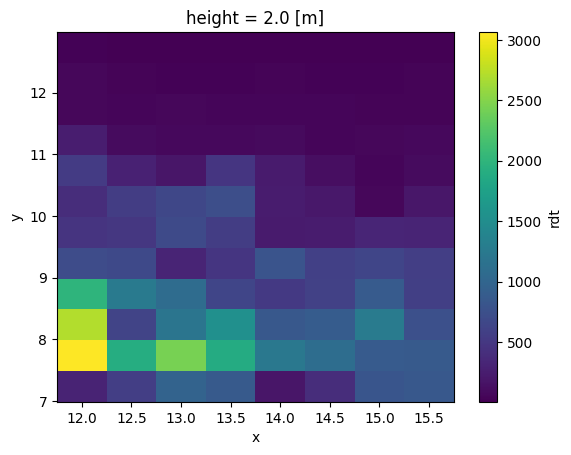

In [277]:
rdt_last_ds["rdt"].mean(dim="time").plot()

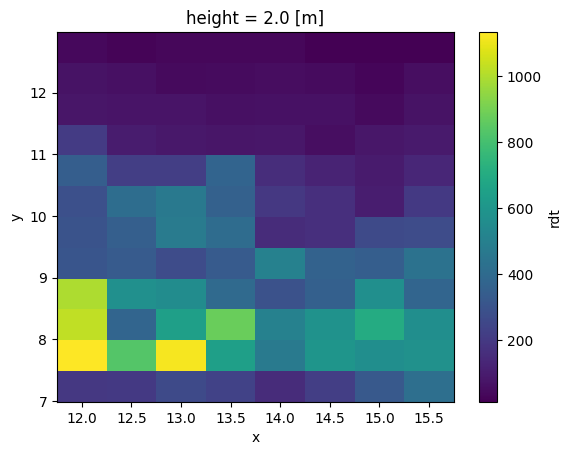

In [273]:
rdt_last_ds["rdt"].std(dim="time").plot()

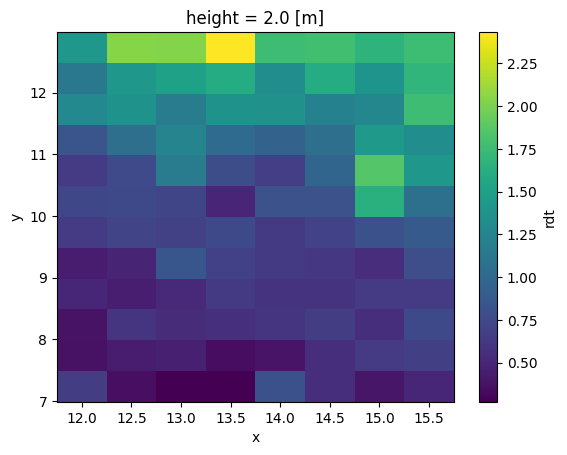

In [270]:
(rdt_last_ds.std(dim="time")["rdt"] / rdt_last_ds.mean(dim="time")["rdt"]).plot()

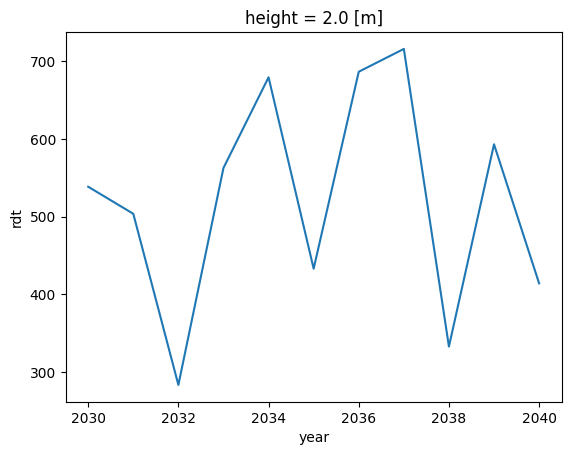

In [289]:
rdt_year_ds["rdt"].mean(dim=["y","x"]).plot()

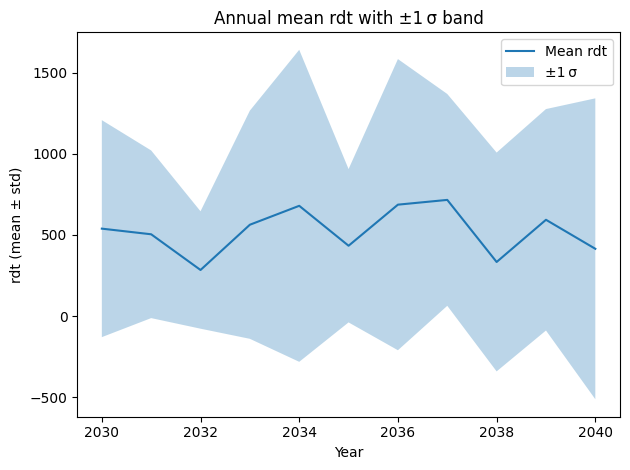

In [290]:
import matplotlib.pyplot as plt

# Assume `rdt_year_ds` is already in the notebook environment
# Compute mean and standard deviation over the spatial dimensions
mean_rdt = rdt_year_ds["rdt"].mean(dim=["y", "x"])
std_rdt  = rdt_year_ds["rdt"].std(dim=["y", "x"])

years = mean_rdt["year"].values

# Create the plot
plt.figure()
plt.plot(years, mean_rdt.values, label="Mean rdt")
plt.fill_between(years,
                 (mean_rdt - std_rdt).values,
                 (mean_rdt + std_rdt).values,
                 alpha=0.3,
                 label="±1 σ")

plt.xlabel("Year")
plt.ylabel("rdt (mean ± std)")
plt.title("Annual mean rdt with ±1 σ band")
plt.legend()
plt.tight_layout()
plt.show()
